# Laboratorium 1: regresja liniowa i kwartet Anscombe’a

Rozwiązania trzech zadań. W VS Code wybierz kernel z `.venv` i uruchom wszystkie komórki.
Wariancje w tabelach mają dzielnik **n − 1**. Wszystkie tabele i wykresy są także w `outputs/lab01.xlsx`, na jednej karcie.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file()
)
LAB_DIR = PROJECT_ROOT / "labs" / "lab01"
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))

from analysis import IMAGE_DIR, OUTPUT_DIR, run_analysis

results = run_analysis()
pd.options.display.float_format = "{:.4f}".format
columns = ["series", "mean_x", "mean_y", "var_x_sample", "var_y_sample", "pearson_r", "beta0", "beta1"]

## Zadanie 1. Kwartet Anscombe’a

Dla czterech serii policzyliśmy średnie, wariancje i korelacje Pearsona. Dopasowaliśmy proste regresji metodą najmniejszych kwadratów.

,series,mean_x,mean_y,var_x_sample,var_y_sample,pearson_r,beta0,beta1
0,I,9.0000,7.5009,11.0000,4.1273,0.8164,3.0001,0.5001
1,II,9.0000,7.5009,11.0000,4.1276,0.8162,3.0009,0.5000
2,III,9.0000,7.5000,11.0000,4.1226,0.8163,3.0025,0.4997
3,IV,9.0000,7.5009,11.0000,4.1232,0.8165,3.0017,0.4999


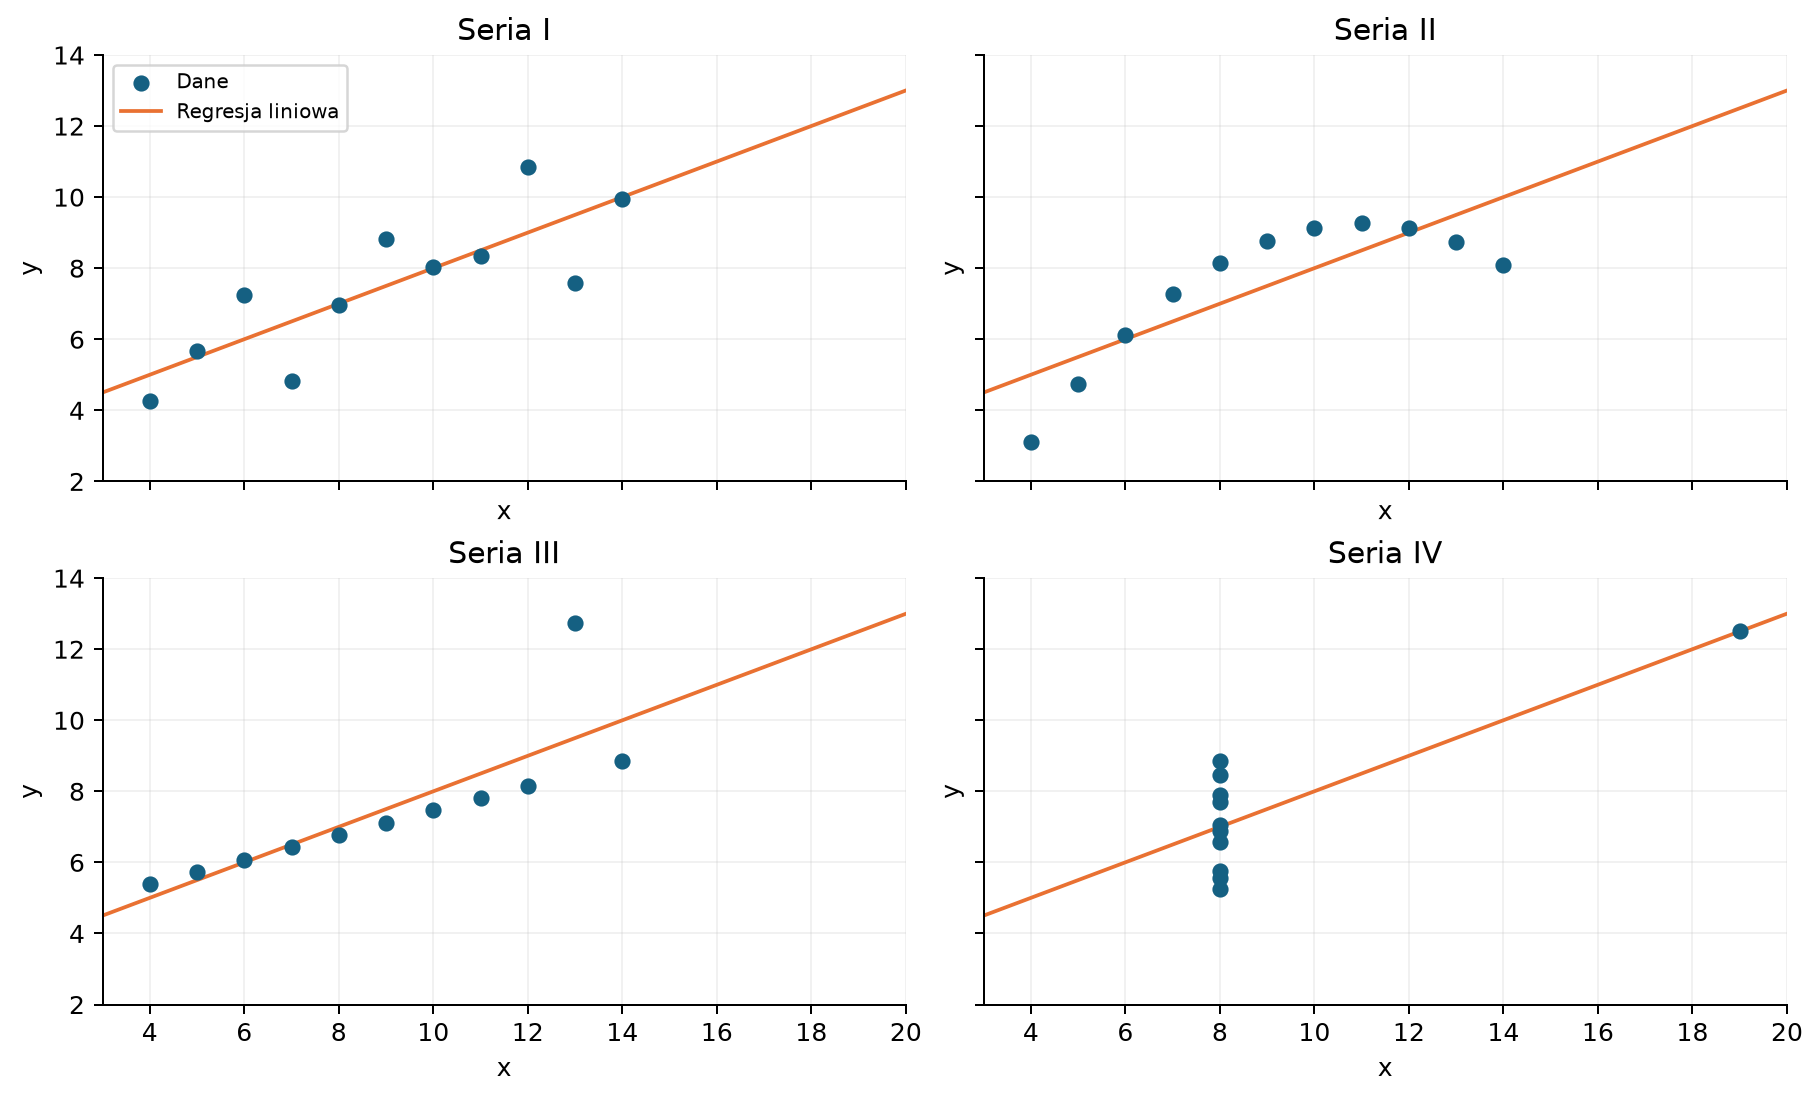

In [2]:
display(results["task1"][columns])
display(Image(filename=str(IMAGE_DIR / "anscombe_regression.png"), width=1000))

**Wnioski**

1. Podobne średnie, wariancje i korelacje nie oznaczają podobnych układów punktów.
2. W serii I zależność jest w przybliżeniu liniowa; w serii II widać zakrzywienie.
3. W serii III jeden punkt zmienia dopasowaną prostą.
4. W serii IV wynik zależy od jedynego punktu z x = 19.
5. Statystyki trzeba uzupełnić wykresem danych.

## Zadanie 2. CSV, JSON, XML i punkt odstający

Zapisaliśmy te same 44 obserwacje w trzech formatach i porównaliśmy rozmiary plików przed kompresją.

In [3]:
display(results["formats"])
record = json.loads((OUTPUT_DIR / "anscombe.json").read_text(encoding="utf-8"))[0]
print(json.dumps(record, ensure_ascii=False))

,file,bytes
0,anscombe.csv,555
1,anscombe.json,1470
2,anscombe.xml,3033


{"series": "I", "x": 10.0, "y": 8.04}


CSV zapisuje tabelę w wierszach. JSON przechowuje tablicę obiektów; `{}` oznacza obiekt, a `[]` tablicę. Klucze i napisy wymagają podwójnych cudzysłowów. Dwukropek oddziela klucz od wartości, a przecinki rozdzielają elementy. Wartości mogą być liczbami, napisami, obiektami, tablicami, `true`, `false` lub `null`. JSON jest często używany w API internetowych i konfiguracji. XML opisuje rekordy znacznikami.

W serii III zastosowaliśmy regułę **1,5 × IQR dla y**. Granice 3,655 i 10,575 wskazały punkt **(13; 12,74)**. Usunęliśmy go i ponownie dopasowaliśmy prostą.

,series,n,beta0,beta1,r_squared
0,Przed,11,3.0025,0.4997,0.6663
1,Po,10,4.0056,0.3454,1.0000


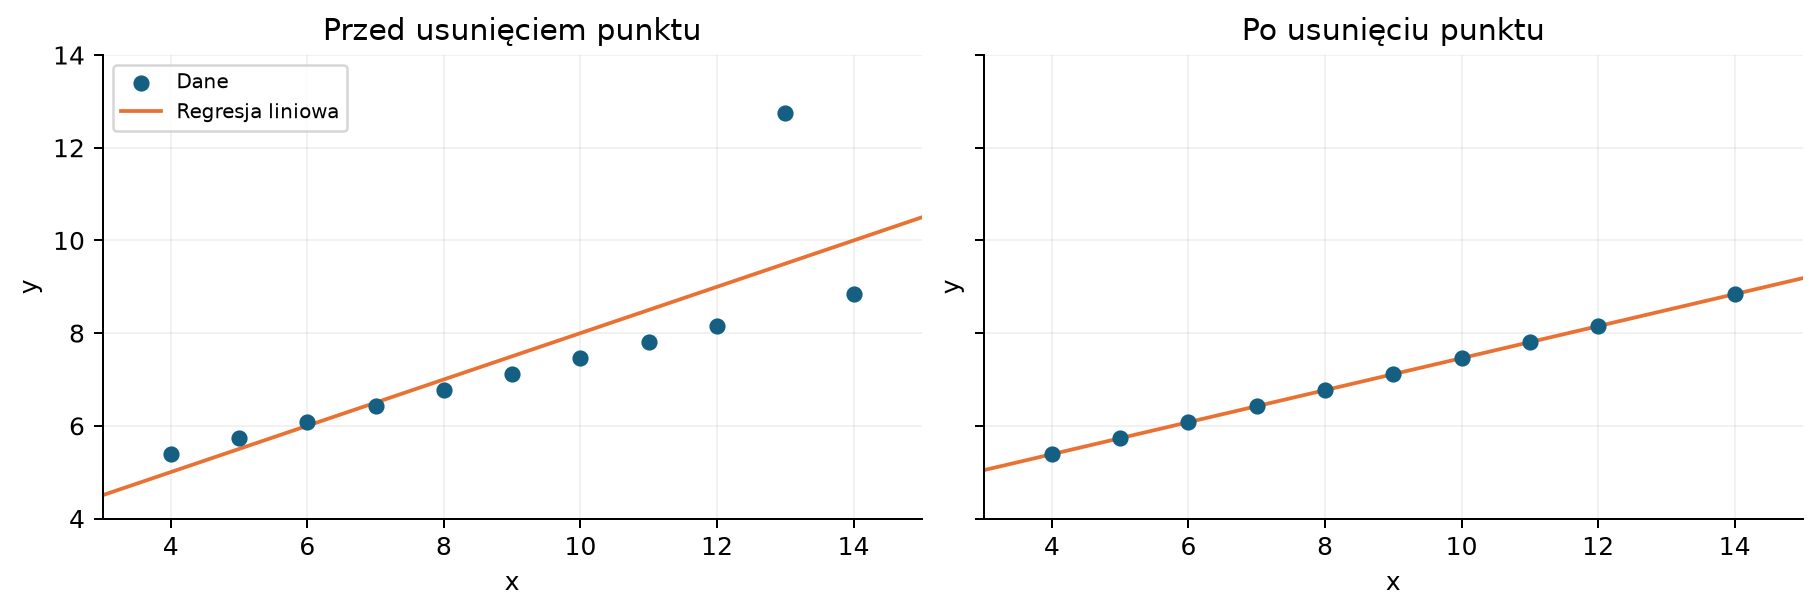

In [4]:
display(results["comparison"][["series", "n", "beta0", "beta1", "r_squared"]].round(6))
display(Image(filename=str(IMAGE_DIR / "outlier_comparison.png"), width=1000))

**Wnioski**

1. CSV ma najmniejszy rozmiar: 555 B; JSON zajmuje 1470 B, a XML 3033 B.
2. Powtarzane nazwy pól i znaczniki zwiększają rozmiar JSON i XML.
3. Wszystkie trzy pliki zawierają te same dane.
4. Reguła IQR wskazała dokładnie jeden punkt odstający.
5. Po usunięciu punktu R² wzrosło z 0,666324 do 0,999993. Pozostałe punkty są niemal współliniowe.
6. Lepsze dopasowanie nie dowodzi błędu pomiaru; warto zachować oba wyniki.

## Zadanie 3. Serie 1, 9 i 10

Dla trzech serii po 142 obserwacje policzyliśmy statystyki i dopasowaliśmy proste regresji.

,series,mean_x,mean_y,var_x_sample,var_y_sample,pearson_r,beta0,beta1
0,seria1,54.2633,47.8323,281.0700,725.5160,-0.0645,53.4530,-0.1036
1,seria9,54.2673,47.8377,280.8980,725.2268,-0.0683,53.7970,-0.1098
2,seria10,54.2687,47.8308,281.2074,725.5334,-0.0686,53.8095,-0.1102


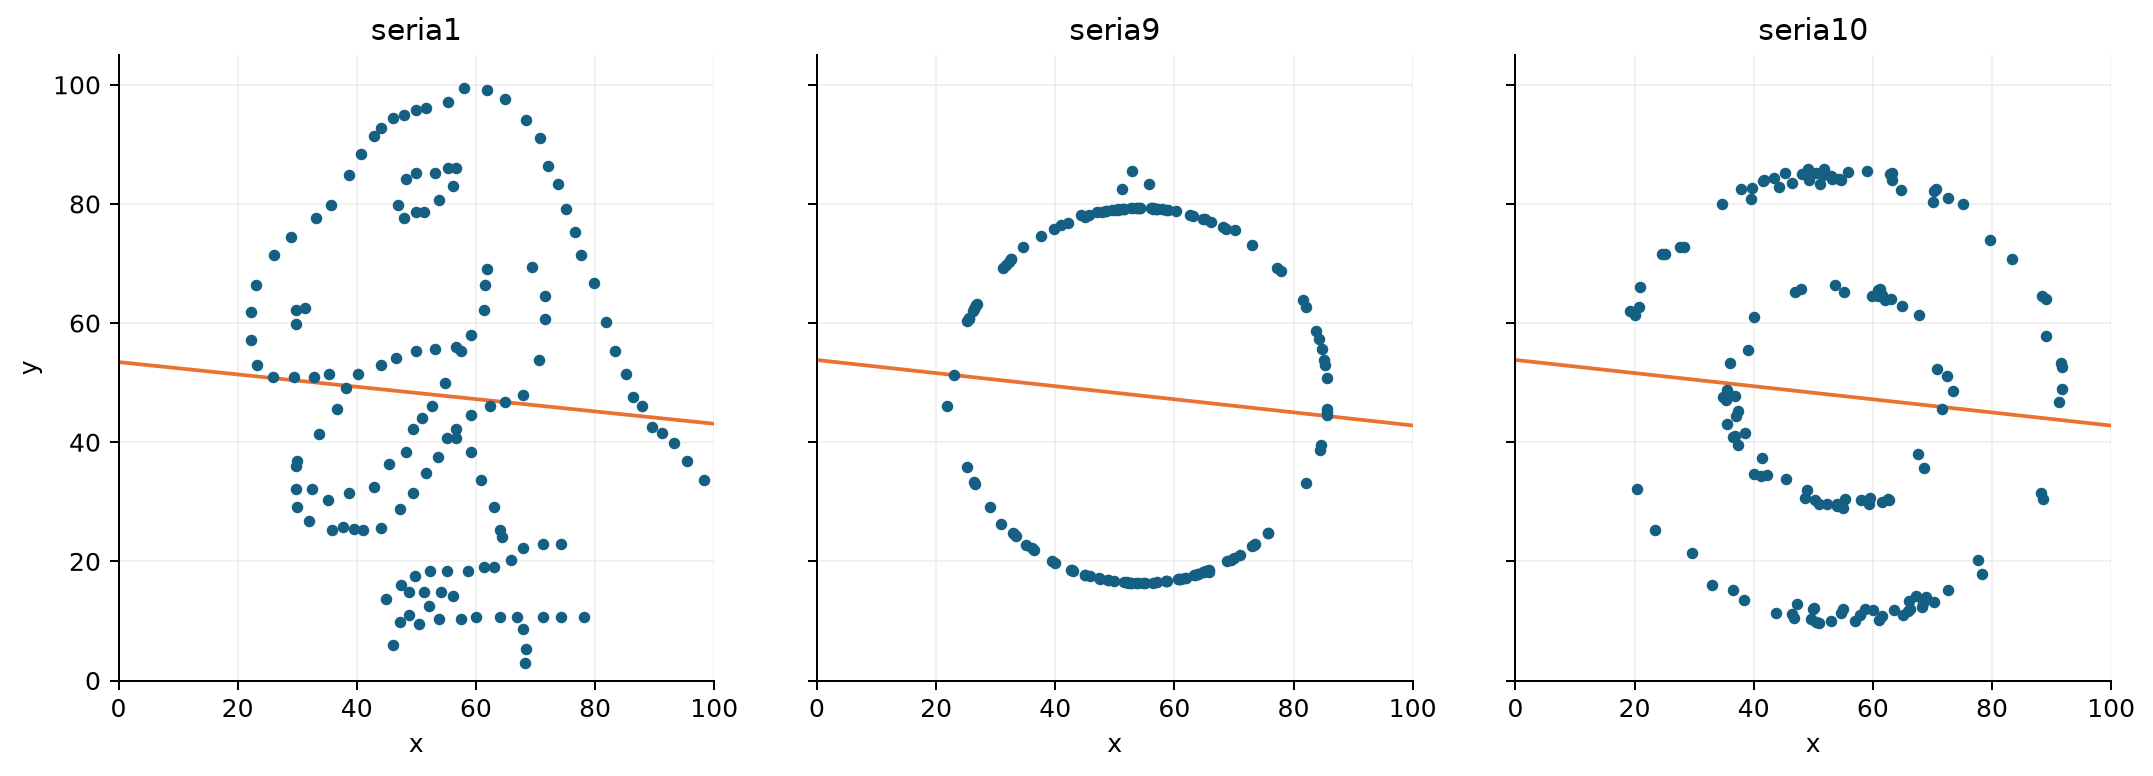

In [5]:
display(results["task3"][columns])
display(Image(filename=str(IMAGE_DIR / "task3_regression.png"), width=1200))

**Wnioski**

1. Serie mają zbliżone średnie i wariancje, mimo różnych kształtów danych.
2. Korelacje od około −0,064 do −0,069 oznaczają bardzo słabą zależność liniową.
3. Mała korelacja nie oznacza braku struktury: widać dinozaura, pierścień i tarczę.
4. Prawie poziome proste nie odtwarzają widocznych kształtów.
5. Wykresy ujawniają różnice niewidoczne w podstawowych statystykach.